# Clustering - Ejemplo Mundiales de Fútbol
---

In [2]:
# Cargar librerías
library(readxl)      # Leer archivos xlsx
library(magrittr)    # Operador pipe %>%
library(tibble)      # Mejor formato de datos
library(dendextend)  # Funciones para dendrogramas
library(factoextra)  # Visualización de clusters
library(dplyr)
library(knitr)
library(tidyr) 
library(cluster)     # Métodos de clustering
library(clusterSim)
library(ggplot2)     # Gráficos
library(gridExtra)

In [3]:
futbol <- read_excel("/Users/ppando/Materias/cs-datos/especializacion/data/futbol.xlsx")

In [4]:
# Asegurar que sea data.frame
futbol <- as.data.frame(futbol)

In [5]:
# Seleccionar variables numéricas (columnas 2 a 11)
futnum <- futbol[, 2:11]

In [6]:
# Eliminar filas con NA
futnum <- na.omit(futnum)

## Dendrograma

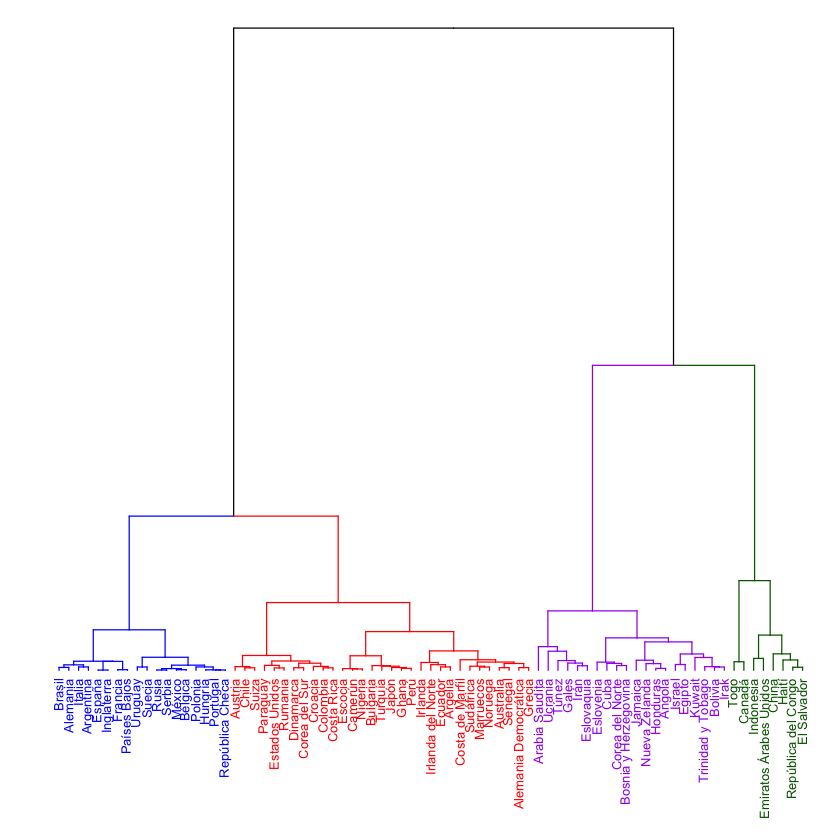

In [7]:
# Crear dendrograma (criterio de Ward)
dend <- futnum %>%
  scale() %>%
  dist() %>%
  hclust(method = "ward.D") %>%
  as.dendrogram()

# Márgenes del gráfico
par(mar = c(6, 1, 0.1, 0.1))

# Personalizar dendrograma
dend %>%
  dendextend::set("branches_k_color", value = c("blue","red","purple","darkgreen"), k = 4) %>%
  dendextend::set("labels_col", value = c("blue","red","purple","darkgreen"), k = 4) %>%
  dendextend::set("labels_cex", 0.65) %>%
  dendextend::set("labels", futbol[,1]) %>%
  plot(axes = FALSE)

In [8]:
#futnum 
head(futnum)

,Mundiales,Puntos,PJ,PG,PE,PP,Rendimiento,GF,GC,Campeón
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,20,227,104,70,17,17,0.73,221,102,1
2,18,218,106,66,20,20,0.69,224,121,1
3,18,156,83,45,21,17,0.63,128,77,1
4,16,140,77,42,14,21,0.61,131,84,1
5,14,99,59,29,12,18,0.56,92,66,1
6,14,98,62,26,20,16,0.53,79,56,1


## Cantidad de clustes e indicadores Codo, Silhouette DBI

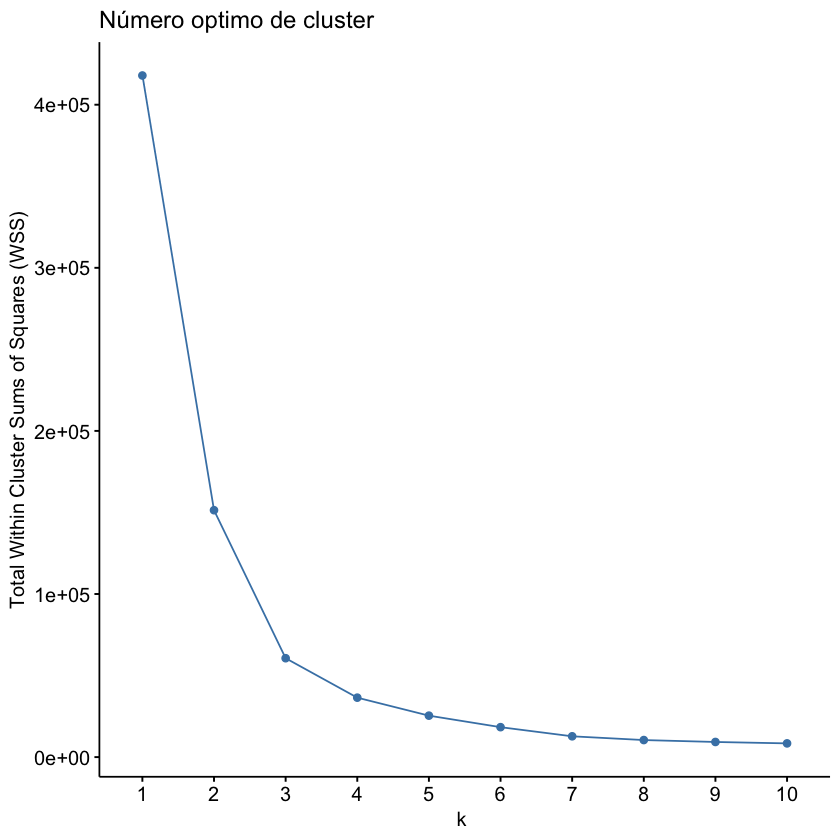

In [9]:
# Utilizar el método de codo para determinar el número 
# de k agrupaciones óptimo 

fviz_nbclust(futnum, 
             FUNcluster = kmeans, 
             method = "wss", 
             k.max = 10, 
             diss = get_dist(futnum, method = "euclidean"), 
             nstart = 50) + 
  labs(title= "Número optimo de cluster") + 
  xlab("k ") + 
  ylab("Total Within Cluster Sums of Squares (WSS)")

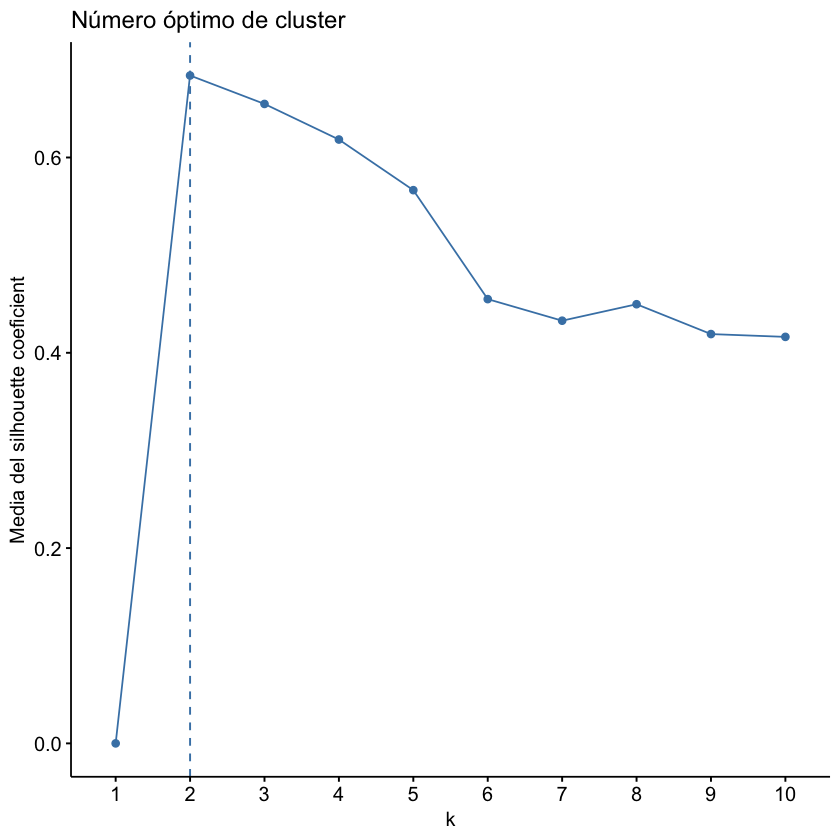

In [10]:
# Utilizar el método de average silhouette para determinar 
# el número de k agrupaciones óptimo 
fviz_nbclust(futnum, 
             kmeans, 
             method = "silhouette",
             k.max = 10, 
             diss = get_dist(futnum, method = "euclidean"), 
             nstart = 50)+ labs(title= "Número óptimo de cluster") + 
  xlab("k") + 
  ylab("Media del silhouette coeficient")

In [11]:
# Evaluar DBI para distintos valores de k
dbi_valores <- sapply(2:10, function(k) {
  km <- kmeans(futnum, centers = k, nstart = 25)
  index.DB(x = futnum, cl = km$cluster, centrotypes = "centroids")$DB
})

In [12]:
# Crear tabla de resultados
tabla_dbi <- data.frame(
    Clusters = 2:10,
    DBI = round(dbi_valores, 3)
)

In [13]:
# Calcular valores DB
dbi_valores <- sapply(2:10, function(k) {
    km <- kmeans(futnum, centers = k, nstart = 50)  # Aumenta nstart para mayor estabilidad
    clusterSim::index.DB(x = futnum, cl = km$cluster, centrotypes = "centroids")$DB
    })

In [14]:
# Imprimir valores
valores_db <- data.frame(k = 2:10, DB = dbi_valores)
print(valores_db)
# Mostrar tabla
print(tabla_dbi)

   k        DB
1  2 0.7409209
2  3 0.5843632
3  4 0.5778283
4  5 0.6514043
5  6 0.5704659
6  7 0.6329225
7  8 0.7110929
8  9 0.7738242
9 10 0.7615036
  Clusters   DBI
1        2 0.741
2        3 0.584
3        4 0.578
4        5 0.651
5        6 0.712
6        7 0.633
7        8 0.711
8        9 0.774
9       10 0.746


In [15]:
# Calcular el índice del mínimo
indice_min <- which.min(dbi_valores)  # devuelve posición en el vector (1 = k=2)
indice_min

[1] 5

In [16]:
# Convertirlo al valor real de k
k_min <- indice_min + 1  # porque el primer valor corresponde a k = 2

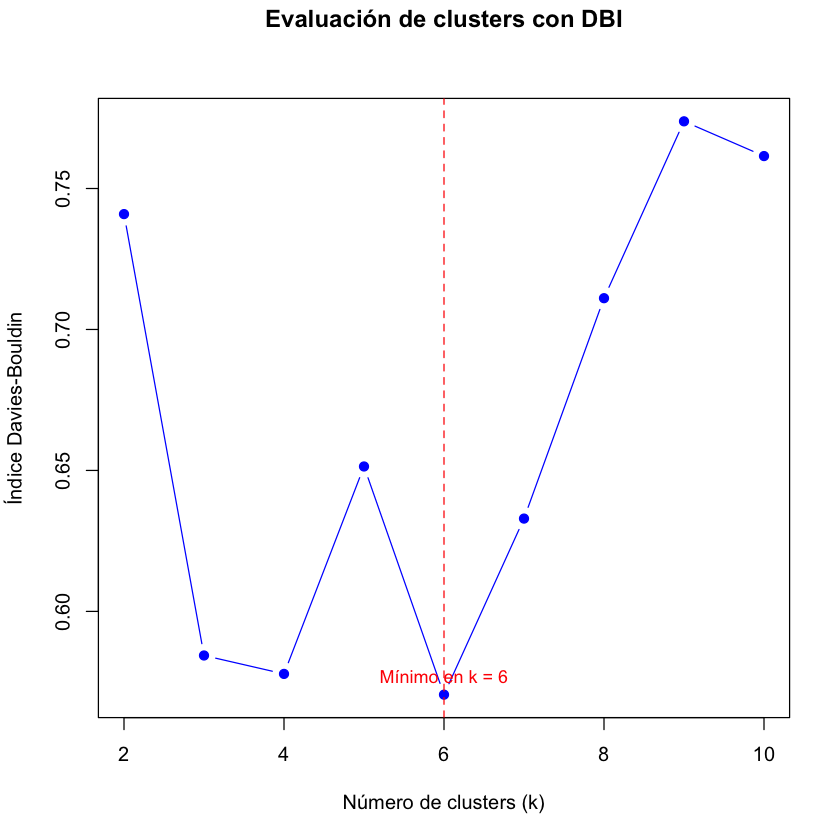

In [17]:
# Graficar los valores de DBI
plot(2:10, 
     dbi_valores, 
     type = "b", 
     pch = 19, 
     col = "blue", 
     xlab = "Número de clusters (k)", 
     ylab = "Índice Davies-Bouldin",
     main = "")
title(main = "Evaluación de clusters con DBI", line = 3)

# Marcar el mínimo correctamente
abline(v = k_min, col = "red", lty = 2)
text(x = k_min, y = dbi_valores[indice_min],
  labels = paste("Mínimo en k =", k_min),
  pos = 3, col = "red", cex = 0.9)

In [18]:
# Encuentra la posición del valor mínimo en el vector
posicion_min <- which.min(dbi_valores)

In [19]:
# Convierte a el valor real de k (sumando 1 porque empezaste en k=2)
#K optimo DB
k_optimo <- posicion_min + 1

## K-means con datos de futbol

In [20]:
# Eliminar registros con datos faltantes
df <- na.omit(futbol)

In [21]:
# Estandarizar las variables (excepto la primera columna con nombres)
df <- scale(df[,-1])

In [22]:
# Poner los nombres de los equipos/jugadores como rownames
rownames(df) <- futbol[,1]

In [23]:
set.seed(123)   # Semilla para reproducibilidad
kmfutbol <- kmeans(df, centers = 4, nstart = 10)

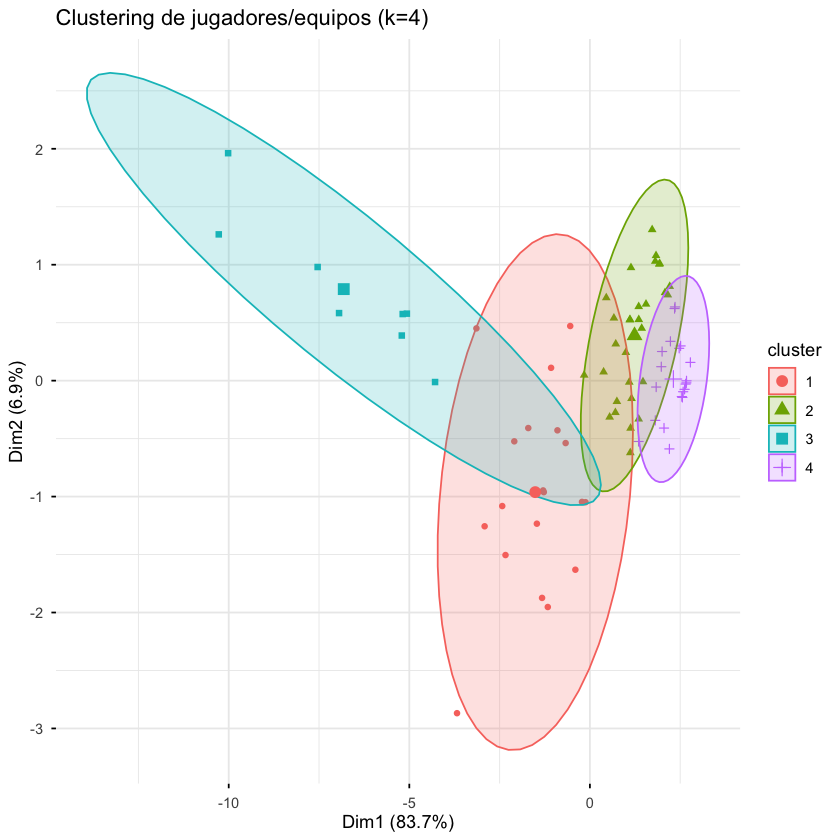

In [24]:
par(mar = c(5, 5, 1, 2))  # Márgenes
fviz_cluster(kmfutbol, data = df,
             geom = "point",
             ellipse.type = "norm",
             ggtheme = theme_minimal(),
             main = "Clustering de jugadores/equipos (k=4)")

In [25]:
# Ajustar márgenes
par(mar = c(5, 5, 1, 2))

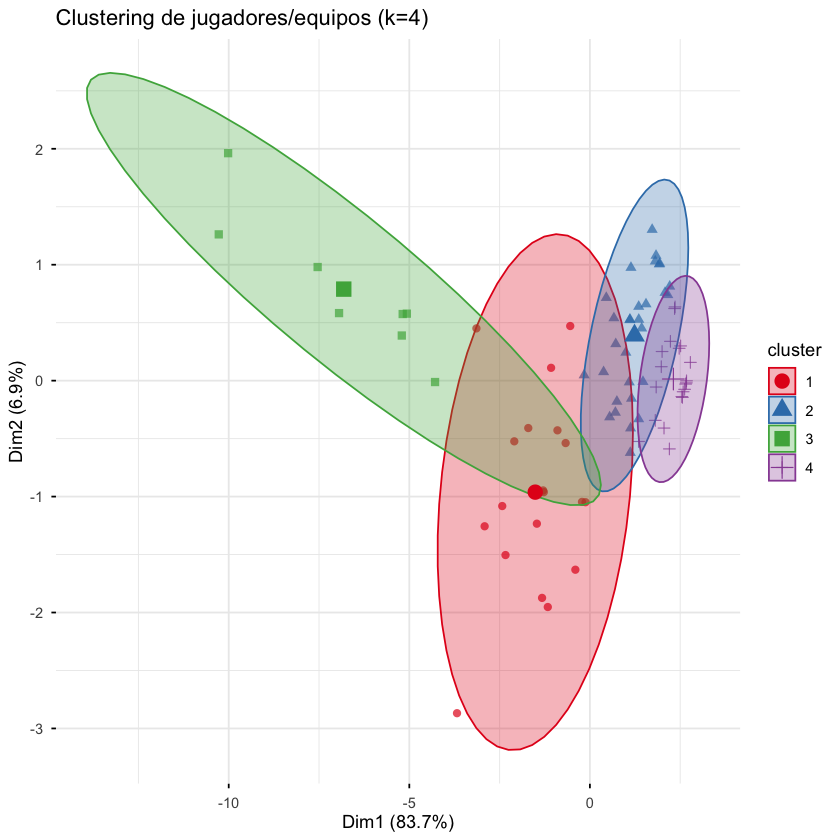

In [26]:
# Crear gráfico con ajustes para reducir superposición
fviz_cluster(kmfutbol, data = df,
             geom = "point",
             ellipse.type = "norm", 
             ellipse.alpha = 0.3,  # Transparencia de elipses
             pointsize = 2,        # Tamaño de puntos más pequeño
             alpha = 0.7,          # Transparencia de puntos
             ggtheme = theme_minimal(),
             main = "Clustering de jugadores/equipos (k=4)") +
  theme(legend.position = "right") +
  scale_color_manual(values = c("#E41A1C", "#377EB8", "#4DAF4A", "#984EA3")) +
  scale_fill_manual(values = c("#E41A1C", "#377EB8", "#4DAF4A", "#984EA3"))

# Visualización de resultados del clustering

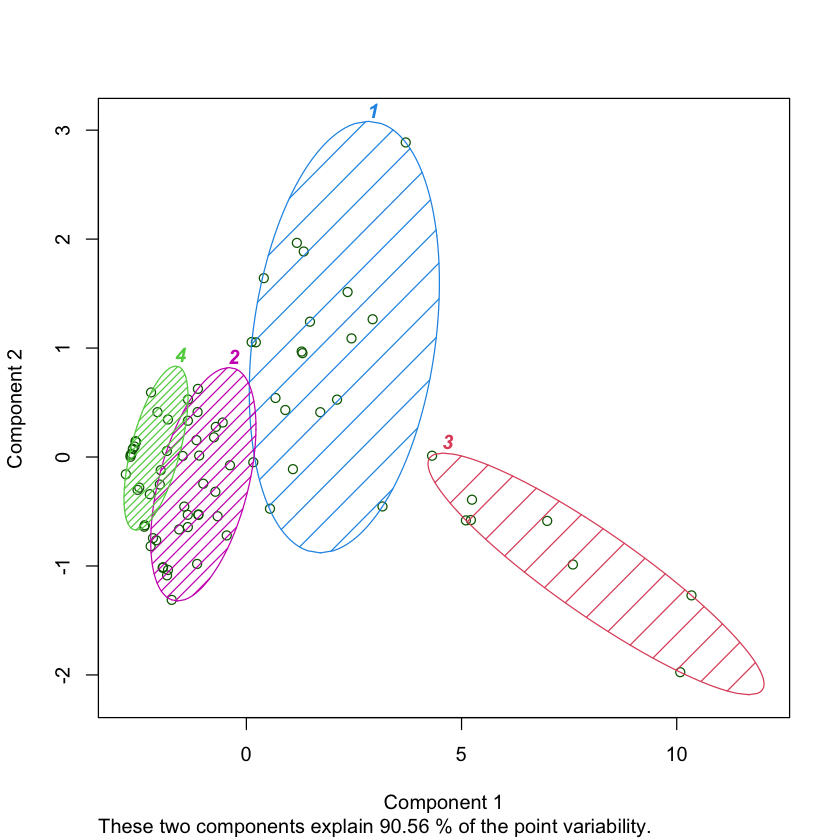

In [27]:
# Dibuja la clasificación (clústeres de k-means)
clusplot(df, 
         kmfutbol$cluster, 
         main=NULL, 
         color=TRUE, 
         shade=TRUE, 
         labels=4,
         lines=0, 
         plotchar=FALSE)

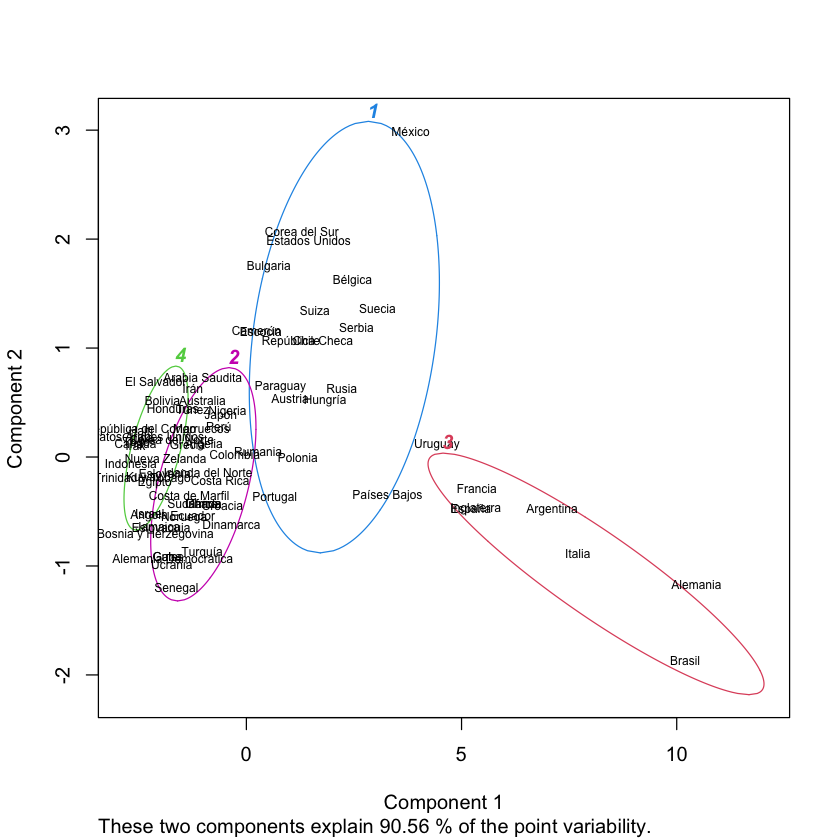

In [28]:
# Dibuja la clasificación con etiquetas
clusplot(df, 
         kmfutbol$cluster, 
         main=NULL, 
         color=TRUE, 
         shade=FALSE, 
         labels=2,
         lines=0, 
         plotchar=FALSE, 
         cex.txt=0.6, 
         col.txt="black", 
         cex=0)

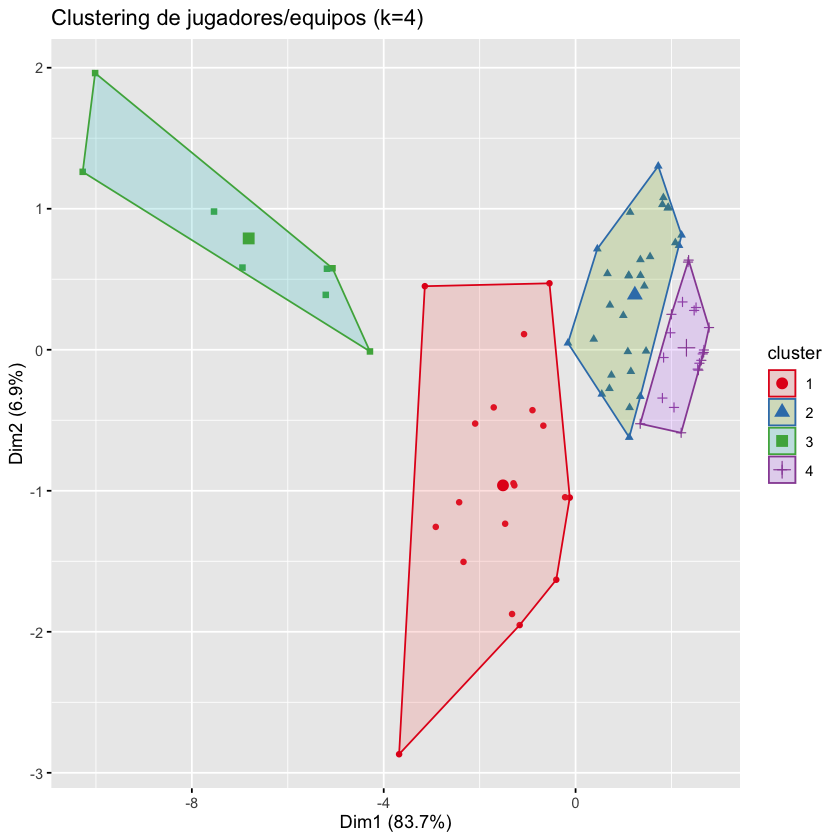

In [29]:
# Clasificación personalizada con factoextra sin las etiquetas
fviz_cluster(kmfutbol, 
             data=df, 
             geom="point", 
             labelsize=8, 
             repel=TRUE) +
  scale_color_brewer(palette="Set1") +
  ggtitle("Clustering de jugadores/equipos (k=4)")

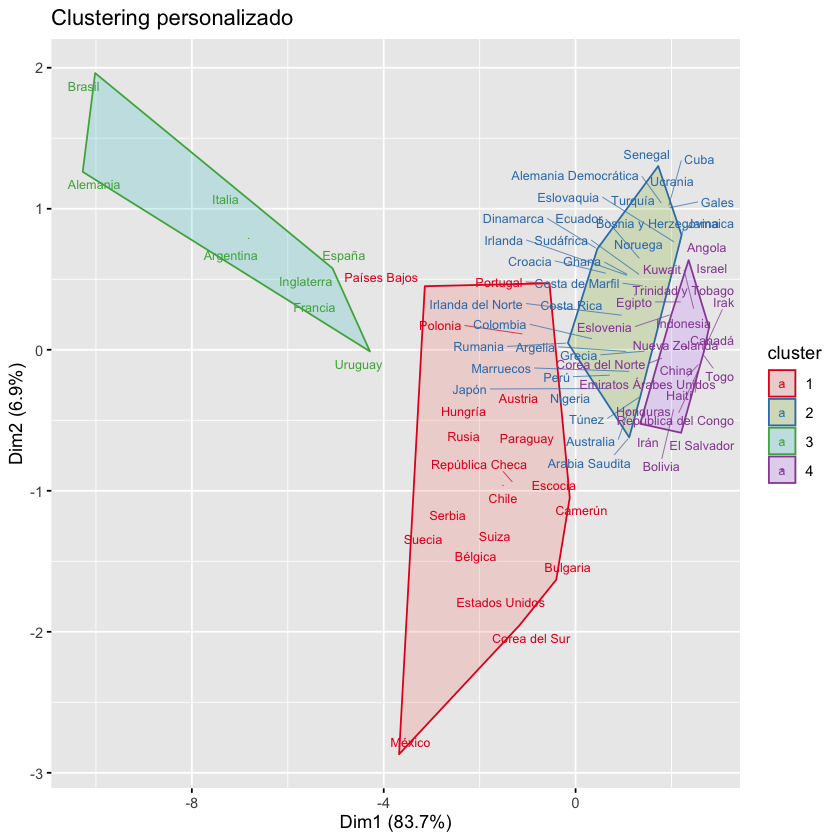

In [30]:
# Clasificación personalizada con factoextra
fviz_cluster(kmfutbol, 
             data=df, 
             geom="text", 
             labelsize=8, 
             repel=TRUE) +
  scale_color_brewer(palette="Set1") +
  ggtitle("Clustering personalizado")

# Guardar el grupo de pertenencia de cada país

In [31]:
Cluster <- kmfutbol$cluster
datos <- data.frame(cbind(futbol, Cluster))
str(datos)

'data.frame':	77 obs. of  12 variables:
 $ País       : chr  "Brasil" "Alemania" "Italia" "Argentina" ...
 $ Mundiales  : num  20 18 18 16 14 14 14 10 12 11 ...
 $ Puntos     : num  227 218 156 140 99 98 96 93 72 61 ...
 $ PJ         : num  104 106 83 77 59 62 59 50 51 46 ...
 $ PG         : num  70 66 45 42 29 26 28 27 20 16 ...
 $ PE         : num  17 20 21 14 12 20 12 12 12 13 ...
 $ PP         : num  17 20 17 21 18 16 19 11 19 17 ...
 $ Rendimiento: num  0.73 0.69 0.63 0.61 0.56 0.53 0.54 0.62 0.47 0.44 ...
 $ GF         : num  221 224 128 131 92 79 106 86 80 74 ...
 $ GC         : num  102 121 77 84 66 56 71 48 71 69 ...
 $ Campeón    : num  1 1 1 1 1 1 1 0 1 0 ...
 $ Cluster    : int  3 3 3 3 3 3 3 1 3 1 ...


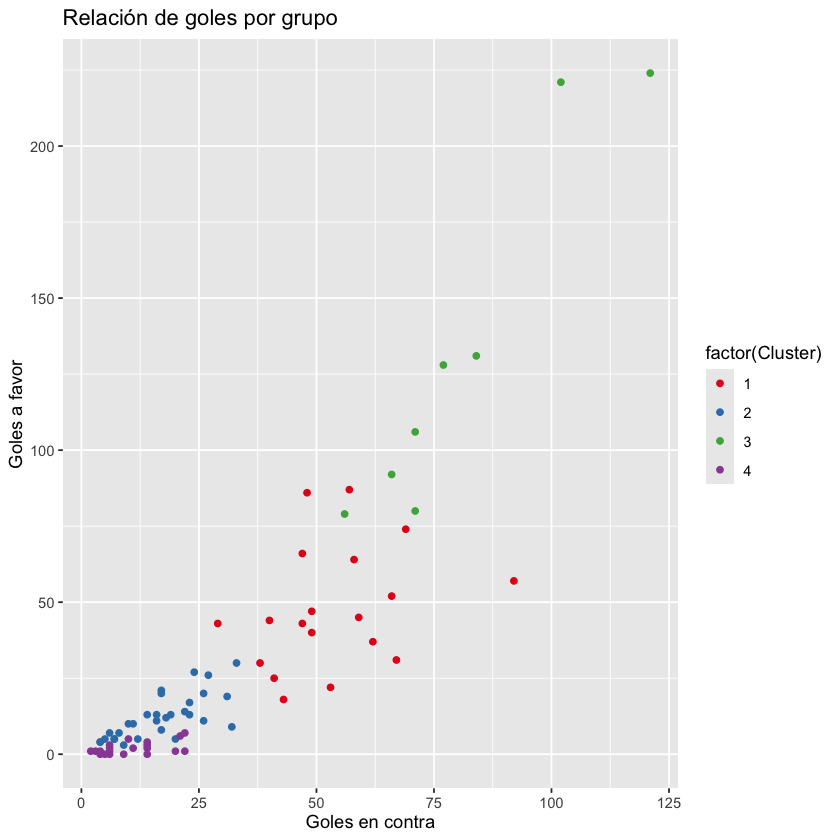

In [32]:
# Gráficas de dispersión con ggplot2
# Relación de goles en contra (GC) y goles a favor (GF) por grupo
ggplot(datos, aes(x=GC, y=GF)) +
  geom_point(aes(colour=factor(Cluster))) +
  scale_color_brewer(palette="Set1") +
  xlab("Goles en contra") +
  ylab("Goles a favor") +
  ggtitle("Relación de goles por grupo")

In [33]:
# Calcular estadísticas para GF y GC por cluster
estadisticas_gf_gc <- datos %>%  
  group_by(Cluster) %>%
  summarise(
    N = n(),
    GF_Media = mean(GF, na.rm = TRUE),
    GF_Mediana = median(GF, na.rm = TRUE),
    GF_Desvio = sd(GF, na.rm = TRUE),
    GC_Media = mean(GC, na.rm = TRUE),
    GC_Mediana = median(GC, na.rm = TRUE),
    GC_Desvio = sd(GC, na.rm = TRUE)
  )

head(datos)

,País,Mundiales,Puntos,PJ,PG,PE,PP,Rendimiento,GF,GC,Campeón,Cluster
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Brasil,Brasil,20,227,104,70,17,17,0.73,221,102,1,3
Alemania,Alemania,18,218,106,66,20,20,0.69,224,121,1,3
Italia,Italia,18,156,83,45,21,17,0.63,128,77,1,3
Argentina,Argentina,16,140,77,42,14,21,0.61,131,84,1,3
España,España,14,99,59,29,12,18,0.56,92,66,1,3
Inglaterra,Inglaterra,14,98,62,26,20,16,0.53,79,56,1,3


In [34]:
# Formatear la tabla para mejor visualización
library(knitr)
cat("\nTABLA FORMATEADA:\n")
kable(estadisticas_gf_gc, digits = 3, align = 'c', 
      caption = "Estadísticas de GF y GC por Cluster")


TABLA FORMATEADA:




Table: Estadísticas de GF y GC por Cluster

| Cluster | N  | GF_Media | GF_Mediana | GF_Desvio | GC_Media | GC_Mediana | GC_Desvio |
|:-------:|:--:|:--------:|:----------:|:---------:|:--------:|:----------:|:---------:|
|    1    | 19 |  47.947  |     44     |  20.134   |  53.368  |    49.0    |  14.221   |
|    2    | 30 |  12.233  |     11     |   7.366   |  16.800  |    17.0    |   8.644   |
|    3    | 8  | 132.625  |    117     |  58.783   |  81.000  |    74.0    |  21.098   |
|    4    | 20 |  2.000   |     1      |   2.077   |  10.650  |    9.5     |   6.651   |

In [35]:
# Si prefieres una tabla más compacta
library(tidyr)
estadisticas_largas <- estadisticas_gf_gc %>%
  pivot_longer(
    cols = -c(Cluster, N),
    names_to = c("Variable", "Estadistica"),
    names_sep = "_",
    values_to = "Valor"
  ) %>%
  pivot_wider(
    names_from = Estadistica,
    values_from = Valor
  )

cat("\nTABLA COMPACTA (VARIABLES EN FILAS):\n")
kable(estadisticas_largas, digits = 3, align = 'c', 
      caption = "Estadísticas de GF y GC por Cluster (formato largo)")


TABLA COMPACTA (VARIABLES EN FILAS):




Table: Estadísticas de GF y GC por Cluster (formato largo)

| Cluster | N  | Variable |  Media  | Mediana | Desvio |
|:-------:|:--:|:--------:|:-------:|:-------:|:------:|
|    1    | 19 |    GF    | 47.947  |  44.0   | 20.134 |
|    1    | 19 |    GC    | 53.368  |  49.0   | 14.221 |
|    2    | 30 |    GF    | 12.233  |  11.0   | 7.366  |
|    2    | 30 |    GC    | 16.800  |  17.0   | 8.644  |
|    3    | 8  |    GF    | 132.625 |  117.0  | 58.783 |
|    3    | 8  |    GC    | 81.000  |  74.0   | 21.098 |
|    4    | 20 |    GF    |  2.000  |   1.0   | 2.077  |
|    4    | 20 |    GC    | 10.650  |   9.5   | 6.651  |

In [36]:
# Crear visualización de los resultados
# Gráfico para GF
plot_gf <- ggplot(datos, aes(x = as.factor(Cluster), y = GF, fill = as.factor(Cluster))) +
  geom_boxplot(alpha = 0.7) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 3, color = "red") +
  labs(title = "Distribución de GF por Cluster", x = "Cluster", y = "GF") +
  theme_minimal() +
  theme(legend.position = "none")

In [37]:
# Gráfico para GC
plot_gc <- ggplot(datos, aes(x = as.factor(Cluster), y = GC, fill = as.factor(Cluster))) +
  geom_boxplot(alpha = 0.7) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 3, color = "red") +
  labs(title = "Distribución de GC por Cluster", x = "Cluster", y = "GC") +
  theme_minimal() +
  theme(legend.position = "none")

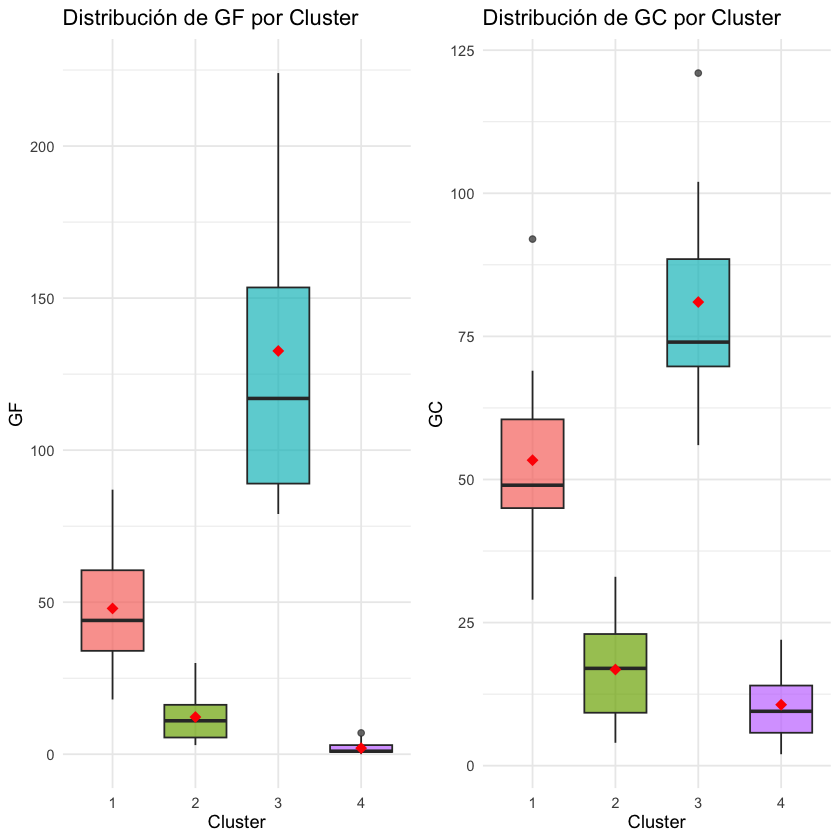

In [38]:
# Mostrar gráficos
grid.arrange(plot_gf, plot_gc, ncol = 2)

In [39]:
# Prueba de Kruskal-Wallis para GF y GC
cat("\nPRUEBAS DE KRUSKAL-WALLIS:\n")
cat("GF - p-valor:", kruskal.test(GF ~ Cluster, data = datos)$p.value, "\n")
cat("GC - p-valor:", kruskal.test(GC ~ Cluster, data = datos)$p.value, "\n")


PRUEBAS DE KRUSKAL-WALLIS:
GF - p-valor: 4.858819e-14 
GC - p-valor: 4.877033e-12 
